# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhamad Chandra Darmawan
- **Email:** muhamadchandra.d19@gmail.com
- **ID Dicoding:** m_chn9

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh musim (season) dan kondisi cuaca (weathersit) terhadap rata-rata jumlah peminjaman sepeda harian di Washington D.C. selama periode 2011 hingga 2012, serta kombinasi musim dan cuaca mana yang menghasilkan rata-rata peminjaman tertinggi?
- **Pertanyaan 2:** Pada jam berapa puncak peminjaman sepeda terjadi pada hari kerja dibandingkan hari libur selama periode 2011 hingga 2012, dan bagaimana perbandingan kontribusi pengguna casual terhadap pengguna registered pada jam puncak tersebut?

## Import Semua Packages/Library yang Digunakan

In [1]:
# Mengimpor library numpy untuk operasi numerik dan array
import numpy as np
# Mengimpor library pandas untuk manipulasi dan analisis data dalam bentuk dataframe
import pandas as pd
# Mengimpor matplotlib pyplot untuk membuat grafik dan visualisasi statis
import matplotlib.pyplot as plt
# Mengimpor seaborn sebagai library visualisasi tingkat tinggi berbasis matplotlib
import seaborn as sns
# Mengimpor modul datetime untuk pengolahan tanggal dan waktu bila diperlukan
from datetime import datetime

# Mengatur gaya visualisasi seaborn menjadi 'whitegrid' agar background chart lebih mudah dibaca
sns.set_style('whitegrid')
# Menetapkan ukuran default figure matplotlib menjadi lebar 12 dan tinggi 6 inci
plt.rcParams['figure.figsize'] = (12, 6)
# Menetapkan ukuran font default seluruh chart menjadi 11
plt.rcParams['font.size'] = 11
# Mengatur pandas agar menampilkan seluruh kolom tanpa dipotong
pd.set_option('display.max_columns', None)

# Menampilkan pesan konfirmasi bahwa seluruh library berhasil dimuat
print('Semua library berhasil dimuat.')

Semua library berhasil dimuat.


## Data Wrangling

### Gathering Data

#### Load df Bike Sharing (day.csv dan hour.csv)

In [2]:
# Membaca berkas day.csv yang berisi data peminjaman sepeda agregat per hari
day_df = pd.read_csv('data/day.csv')
# Membaca berkas hour.csv yang berisi data peminjaman sepeda agregat per jam
hour_df = pd.read_csv('data/hour.csv')

# Menampilkan keterangan singkat untuk dataset harian
print('Dataset day.csv (peminjaman per hari):')
# Menampilkan jumlah baris dan kolom dataset day_df
print(f'Jumlah baris: {day_df.shape[0]}, Jumlah kolom: {day_df.shape[1]}')
# Menampilkan lima baris pertama day_df untuk memeriksa isi awal data
day_df.head()

Dataset day.csv (peminjaman per hari):
Jumlah baris: 731, Jumlah kolom: 16


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Dataset `day.csv` memuat 731 baris yang mencatat total peminjaman sepeda per hari selama periode 2011 hingga 2012.
- Dataset `hour.csv` memuat 17.379 baris yang mencatat peminjaman sepeda per jam pada rentang tanggal yang sama.
- Kedua dataset memiliki kolom yang mirip, kecuali kolom `hr` yang hanya terdapat pada `hour.csv`, sehingga dataset per jam dapat dipakai untuk analisis pola intra-hari.

### Assessing Data

#### Identifying missing value, duplicate, tipe data, dan outlier

In [3]:
# Menampilkan label pemisah untuk keterbacaan output
print('=== INFO day_df ===')
# Memanggil method info() untuk melihat tipe data dan jumlah non-null setiap kolom day_df
day_df.info()

# Menampilkan label untuk pengecekan missing value day_df
print('\nJumlah missing value day_df:')
# Menghitung banyaknya missing value pada setiap kolom day_df
print(day_df.isna().sum())

# Menghitung dan menampilkan banyaknya baris duplikat pada day_df
print(f'\nJumlah baris duplikat day_df: {day_df.duplicated().sum()}')

# Menampilkan label pemisah untuk dataset per jam
print('\n=== INFO hour_df ===')
# Memanggil method info() untuk melihat tipe data dan jumlah non-null setiap kolom hour_df
hour_df.info()

# Menampilkan label untuk pengecekan missing value hour_df
print('\nJumlah missing value hour_df:')
# Menghitung banyaknya missing value pada setiap kolom hour_df
print(hour_df.isna().sum())

# Menghitung dan menampilkan banyaknya baris duplikat pada hour_df
print(f'\nJumlah baris duplikat hour_df: {hour_df.duplicated().sum()}')

# Menampilkan label statistik deskriptif
print('\nStatistik deskriptif day_df:')
# Menampilkan ringkasan statistik (count, mean, std, min, quartile, max) day_df
day_df.describe()

=== INFO day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

Jumlah missing value day_df:
instant       0
dteday        0
season        0
yr        

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- Mengubah tipe data kolom `dteday` dari object menjadi datetime agar analisis berbasis waktu lebih mudah dilakukan.
- Menambahkan kolom label (season_label, weather_label, weekday_label, month_label, year_label) agar hasil visualisasi lebih mudah dibaca stakeholder.
- Mendenormalisasi kolom suhu (temp dan atemp), kelembaban (hum), serta kecepatan angin (windspeed) ke satuan asli agar interpretasi lebih intuitif.
- Tidak diperlukan penanganan missing value maupun duplikat karena kedua dataset bersih dari kedua masalah tersebut.

**Insight:**
- Tidak ditemukan missing value pada kedua dataset sehingga tahap imputasi tidak diperlukan.
- Tidak ditemukan baris duplikat pada kedua dataset.
- Kolom `dteday` saat ini bertipe object, padahal secara semantik merupakan tanggal, sehingga perlu dikonversi ke datetime.
- Kolom numerik seperti `temp`, `atemp`, `hum`, dan `windspeed` masih dalam bentuk ternormalisasi (0 sampai 1), sehingga perlu dikembalikan ke satuan asli untuk mempermudah interpretasi.

### Cleaning Data

#### Fixing tipe data dan menambahkan kolom label

In [4]:
# Mengonversi kolom dteday day_df dari string menjadi datetime agar siap dipakai untuk analisis time series
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
# Mengonversi kolom dteday hour_df dari string menjadi datetime dengan alasan yang sama
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# Membuat kamus pemetaan kode musim ke label bahasa Indonesia agar lebih mudah dibaca
season_map = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
# Membuat kamus pemetaan kode cuaca ke label deskriptif
weather_map = {1: 'Cerah', 2: 'Berawan/Berkabut', 3: 'Hujan/Salju Ringan', 4: 'Cuaca Ekstrem'}
# Membuat kamus pemetaan kode hari (0=Minggu sampai 6=Sabtu) ke nama hari
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
# Membuat kamus pemetaan nomor bulan ke singkatan nama bulan
month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
             7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}
# Membuat kamus pemetaan kode tahun (0=2011, 1=2012) ke tahun kalender sesungguhnya
year_map = {0: 2011, 1: 2012}

# Melakukan perulangan untuk kedua dataframe agar transformasi dilakukan konsisten
for df in [day_df, hour_df]:
    # Menambahkan kolom season_label hasil mapping kode musim ke label bahasa Indonesia
    df['season_label'] = df['season'].map(season_map)
    # Menambahkan kolom weather_label hasil mapping kode cuaca ke label deskriptif
    df['weather_label'] = df['weathersit'].map(weather_map)
    # Menambahkan kolom weekday_label hasil mapping kode hari ke nama hari
    df['weekday_label'] = df['weekday'].map(weekday_map)
    # Menambahkan kolom month_label hasil mapping nomor bulan ke singkatan nama bulan
    df['month_label'] = df['mnth'].map(month_map)
    # Menambahkan kolom year_label hasil mapping kode tahun ke tahun kalender
    df['year_label'] = df['yr'].map(year_map)
    # Mendenormalisasi kolom temp kembali ke satuan Celsius dengan mengalikan nilai maksimum 41
    df['temp_actual'] = df['temp'] * 41
    # Mendenormalisasi kolom atemp (feeling temperature) kembali ke satuan Celsius dengan mengalikan 50
    df['atemp_actual'] = df['atemp'] * 50
    # Mendenormalisasi kolom hum (kelembaban) menjadi persentase dengan mengalikan 100
    df['hum_actual'] = df['hum'] * 100
    # Mendenormalisasi kolom windspeed menjadi km per jam dengan mengalikan 67
    df['windspeed_actual'] = df['windspeed'] * 67

# Menampilkan pesan konfirmasi bahwa proses cleaning selesai
print('Data berhasil dibersihkan dan diperkaya dengan kolom label.')
# Menampilkan label untuk preview data
print('\nContoh hasil cleaning day_df:')
# Menampilkan beberapa kolom hasil cleaning untuk verifikasi
day_df[['dteday', 'season_label', 'weather_label', 'temp_actual', 'hum_actual', 'cnt']].head()

Data berhasil dibersihkan dan diperkaya dengan kolom label.

Contoh hasil cleaning day_df:


,dteday,season_label,weather_label,temp_actual,hum_actual,cnt
0,2011-01-01,Semi,Berawan/Berkabut,14.110847,80.5833,985
1,2011-01-02,Semi,Berawan/Berkabut,14.902598,69.6087,801
2,2011-01-03,Semi,Cerah,8.050924,43.7273,1349
3,2011-01-04,Semi,Cerah,8.200000,59.0435,1562
4,2011-01-05,Semi,Cerah,9.305237,43.6957,1600


**Insight:**
- Kolom `dteday` berhasil dikonversi ke datetime sehingga analisis berbasis tanggal dapat dilakukan tanpa parsing manual.
- Penambahan kolom label memudahkan interpretasi visualisasi karena pembaca tidak perlu menghafal arti kode numerik.
- Denormalisasi kolom cuaca mengubah suhu ke rentang Celsius (0 sampai 41), kelembaban ke persentase (0 sampai 100), dan kecepatan angin ke km/jam (0 sampai 67).

## Exploratory Data Analysis (EDA)

### Explore pola peminjaman berdasarkan musim, cuaca, jam, dan tipe pengguna

In [5]:
# Menampilkan label ringkasan untuk statistik per musim
print('Rata-rata, total, dan jumlah hari peminjaman sepeda per musim:')
# Menghitung agregasi rata-rata, total, dan jumlah hari peminjaman untuk tiap musim
season_summary = day_df.groupby('season_label')['cnt'].agg(['mean', 'sum', 'count']).round(2)
# Mengganti nama kolom agar lebih deskriptif berbahasa Indonesia
season_summary.columns = ['rata_rata', 'total', 'jumlah_hari']
# Menampilkan ringkasan diurutkan dari rata-rata tertinggi ke terendah
print(season_summary.sort_values('rata_rata', ascending=False))

# Menampilkan label ringkasan untuk statistik per kondisi cuaca
print('\nRata-rata peminjaman per kondisi cuaca:')
# Menghitung agregasi rata-rata, total, dan jumlah hari untuk tiap kondisi cuaca
weather_summary = day_df.groupby('weather_label')['cnt'].agg(['mean', 'sum', 'count']).round(2)
# Mengganti nama kolom agar lebih deskriptif
weather_summary.columns = ['rata_rata', 'total', 'jumlah_hari']
# Menampilkan ringkasan diurutkan dari rata-rata tertinggi ke terendah
print(weather_summary.sort_values('rata_rata', ascending=False))

# Menampilkan label untuk perbandingan tahunan
print('\nTotal pengguna casual vs registered per tahun:')
# Mengelompokkan total peminjaman casual, registered, dan cnt berdasarkan tahun
yearly_user = day_df.groupby('year_label')[['casual', 'registered', 'cnt']].sum()
# Menghitung persentase pertumbuhan pengguna casual tahun ke tahun
yearly_user['pertumbuhan_casual_%'] = yearly_user['casual'].pct_change() * 100
# Menghitung persentase pertumbuhan pengguna registered tahun ke tahun
yearly_user['pertumbuhan_registered_%'] = yearly_user['registered'].pct_change() * 100
# Menampilkan tabel ringkasan dengan dua desimal
print(yearly_user.round(2))

# Menampilkan label untuk matriks korelasi variabel cuaca
print('\nKorelasi variabel cuaca dengan jumlah peminjaman:')
# Menghitung matriks korelasi antara variabel cuaca aktual dan total peminjaman
corr_matrix = day_df[['temp_actual', 'atemp_actual', 'hum_actual', 'windspeed_actual', 'cnt']].corr()
# Menampilkan matriks korelasi dibulatkan tiga desimal
print(corr_matrix.round(3))

# Menampilkan label untuk pola per jam
print('\nRata-rata peminjaman per jam (hari kerja vs hari libur):')
# Menghitung rata-rata peminjaman per jam dipisahkan antara hari kerja dan hari libur
hourly_summary = hour_df.groupby(['hr', 'workingday'])['cnt'].mean().unstack().round(2)
# Memberi label kolom 0 dan 1 menjadi deskriptif
hourly_summary.columns = ['Libur/Akhir Pekan', 'Hari Kerja']
# Menampilkan tabel ringkasan jam
print(hourly_summary)

Rata-rata, total, dan jumlah hari peminjaman sepeda per musim:
              rata_rata    total  jumlah_hari
season_label                                 
Gugur           5644.30  1061129          188
Panas           4992.33   918589          184
Dingin          4728.16   841613          178
Semi            2604.13   471348          181

Rata-rata peminjaman per kondisi cuaca:
                    rata_rata    total  jumlah_hari
weather_label                                      
Cerah                 4876.79  2257952          463
Berawan/Berkabut      4035.86   996858          247
Hujan/Salju Ringan    1803.29    37869           21

Total pengguna casual vs registered per tahun:
            casual  registered      cnt  pertumbuhan_casual_%  \
year_label                                                      
2011        247252      995851  1243103                   NaN   
2012        372765     1676811  2049576                 50.76   

            pertumbuhan_registered_%  
year_label  

**Insight:**
- Musim Gugur mencatat rata-rata peminjaman harian tertinggi sebesar 5.644 sepeda, sedangkan musim Semi hanya 2.604 sepeda, yang menunjukkan selisih lebih dari dua kali lipat.
- Hari dengan cuaca Cerah menghasilkan rata-rata 4.877 peminjaman, sementara hari dengan Hujan/Salju Ringan hanya 1.803 peminjaman.
- Total peminjaman tahun 2012 naik menjadi 2.049.576 dari 1.243.103 pada tahun 2011, dengan pertumbuhan pengguna registered sebesar 68,4 persen dan pengguna casual sebesar 50,8 persen.
- Variabel suhu (`temp_actual`) memiliki korelasi positif tertinggi terhadap jumlah peminjaman sebesar 0,627, sedangkan kelembaban dan kecepatan angin menunjukkan korelasi negatif.
- Pola peminjaman per jam menunjukkan dua puncak khas hari kerja pada pukul 08.00 dan 17.00, sementara hari libur memperlihatkan puncak tunggal pada tengah hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pengaruh Musim dan Cuaca Terhadap Peminjaman Sepeda Harian

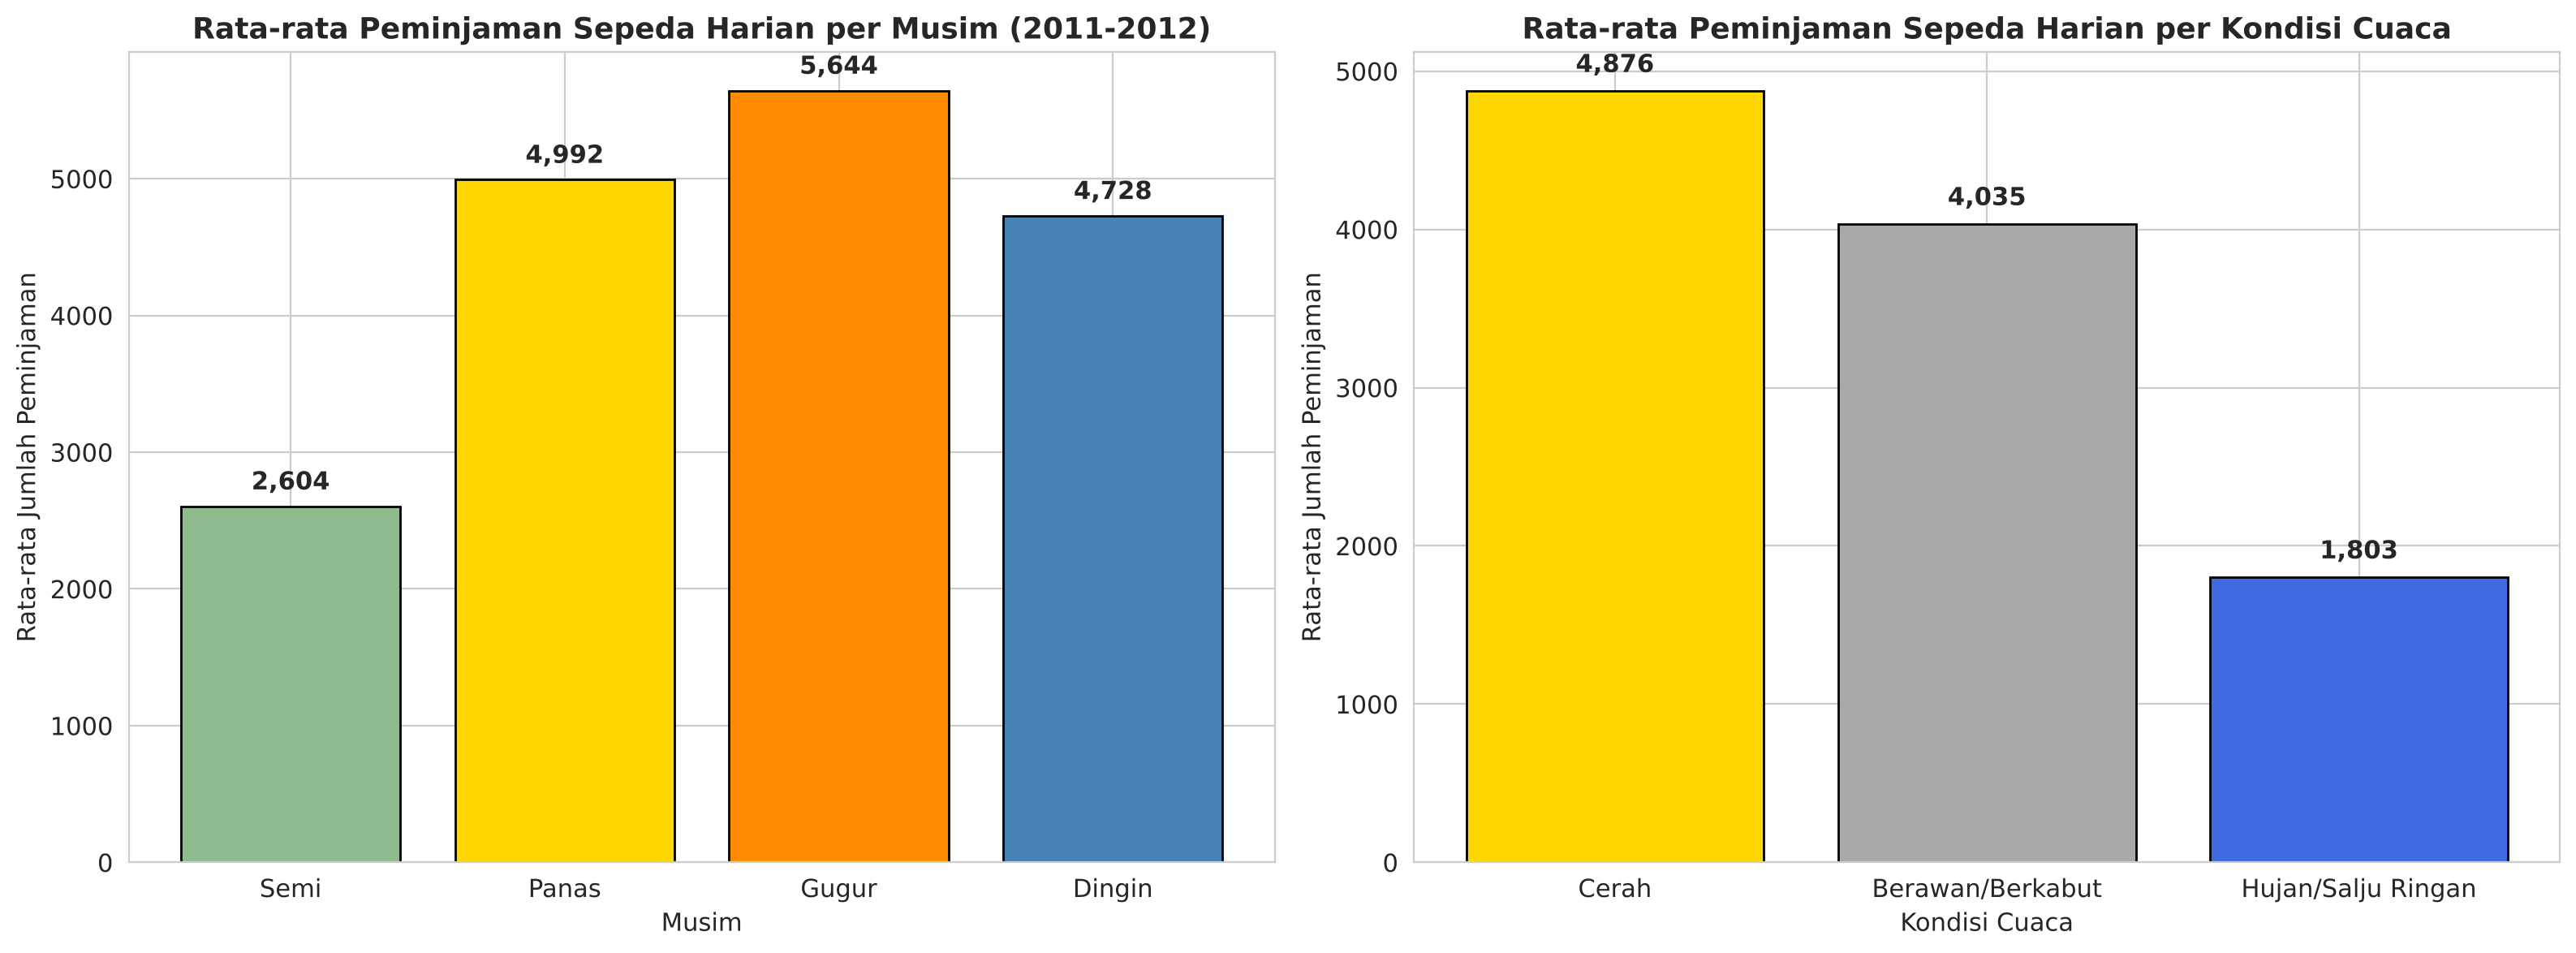

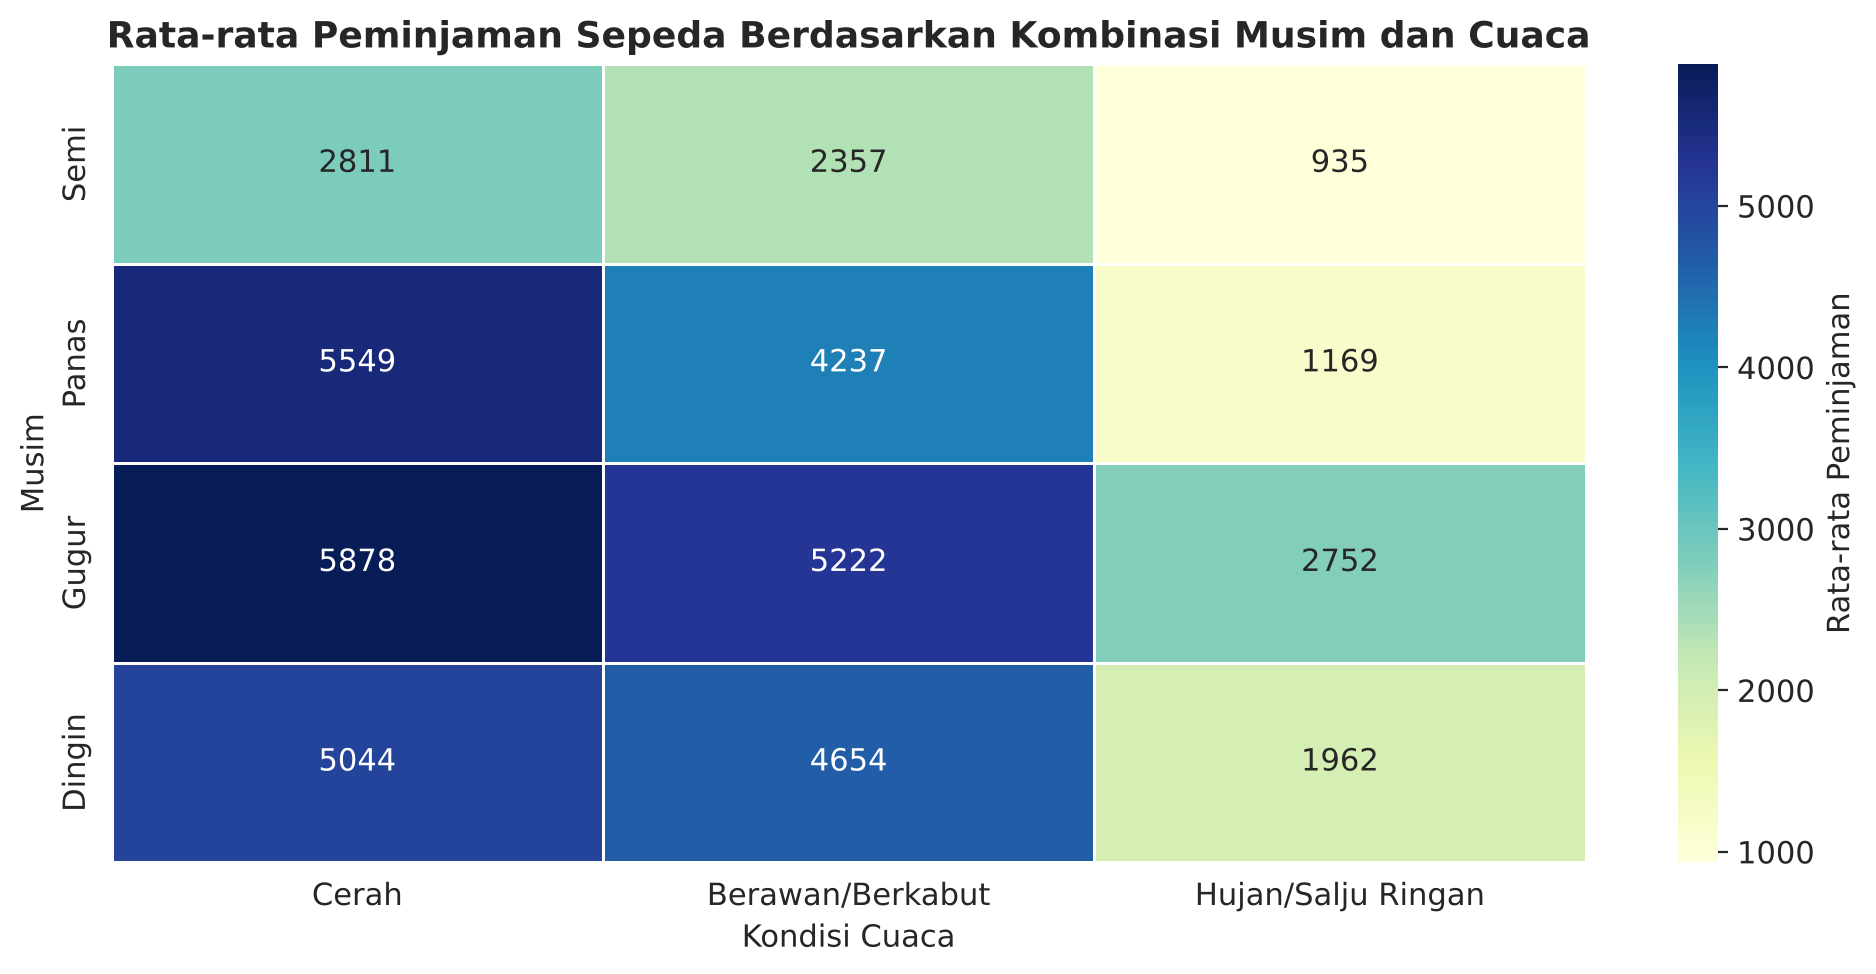

In [6]:
# Membuat figure dengan dua subplot berdampingan untuk membandingkan musim dan cuaca
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Menentukan urutan musim agar sumbu x mengikuti siklus tahunan
season_order = ['Semi', 'Panas', 'Gugur', 'Dingin']
# Menghitung rata-rata peminjaman per musim dan mengurutkannya sesuai season_order
season_avg = day_df.groupby('season_label')['cnt'].mean().reindex(season_order)
# Menentukan warna khas yang mewakili setiap musim agar visualisasi intuitif
colors_season = ['#8FBC8F', '#FFD700', '#FF8C00', '#4682B4']
# Menggambar bar chart rata-rata peminjaman per musim pada subplot kiri
bars1 = axes[0].bar(season_avg.index, season_avg.values, color=colors_season, edgecolor='black')
# Memberi judul subplot kiri dengan ukuran font dan bold agar menonjol
axes[0].set_title('Rata-rata Peminjaman Sepeda Harian per Musim (2011-2012)',
                  fontsize=13, fontweight='bold')
# Memberi label sumbu x pada subplot kiri
axes[0].set_xlabel('Musim', fontsize=11)
# Memberi label sumbu y pada subplot kiri
axes[0].set_ylabel('Rata-rata Jumlah Peminjaman', fontsize=11)
# Melakukan perulangan untuk menambahkan anotasi nilai di atas setiap batang
for bar in bars1:
    # Mengambil tinggi batang saat ini sebagai posisi anotasi
    height = bar.get_height()
    # Menulis angka rata-rata di atas batang untuk kemudahan pembacaan
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 80,
                 f'{int(height):,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Menentukan urutan kondisi cuaca dari yang paling cerah ke paling buruk
weather_order = ['Cerah', 'Berawan/Berkabut', 'Hujan/Salju Ringan']
# Menghitung rata-rata peminjaman per kondisi cuaca mengikuti weather_order
weather_avg = day_df.groupby('weather_label')['cnt'].mean().reindex(weather_order)
# Memilih warna sesuai intensitas cuaca (kuning cerah, abu berawan, biru hujan)
colors_weather = ['#FFD700', '#A9A9A9', '#4169E1']
# Menggambar bar chart rata-rata peminjaman per kondisi cuaca pada subplot kanan
bars2 = axes[1].bar(weather_avg.index, weather_avg.values, color=colors_weather, edgecolor='black')
# Memberi judul subplot kanan
axes[1].set_title('Rata-rata Peminjaman Sepeda Harian per Kondisi Cuaca',
                  fontsize=13, fontweight='bold')
# Memberi label sumbu x pada subplot kanan
axes[1].set_xlabel('Kondisi Cuaca', fontsize=11)
# Memberi label sumbu y pada subplot kanan
axes[1].set_ylabel('Rata-rata Jumlah Peminjaman', fontsize=11)
# Melakukan perulangan untuk menambahkan anotasi nilai pada setiap batang cuaca
for bar in bars2:
    # Mengambil tinggi batang saat ini
    height = bar.get_height()
    # Menulis nilai rata-rata di atas batang
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 80,
                 f'{int(height):,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Menyesuaikan jarak antar subplot agar tidak tumpang tindih
plt.tight_layout()
# Menampilkan chart pada notebook
plt.show()

# Membangun tabel pivot rata-rata peminjaman sebagai dasar heatmap musim vs cuaca
pivot_table = day_df.pivot_table(values='cnt', index='season_label',
                                  columns='weather_label', aggfunc='mean').reindex(season_order)
# Mengurutkan kolom pivot mengikuti urutan cuaca yang telah ditetapkan
pivot_table = pivot_table[weather_order]

# Membuat figure baru khusus untuk heatmap
plt.figure(figsize=(10, 5))
# Menggambar heatmap dengan anotasi nilai dan skema warna YlGnBu
sns.heatmap(pivot_table, annot=True, fmt='.0f', cmap='YlGnBu',
            cbar_kws={'label': 'Rata-rata Peminjaman'}, linewidths=0.5)
# Memberi judul heatmap yang menegaskan kombinasi musim dan cuaca
plt.title('Rata-rata Peminjaman Sepeda Berdasarkan Kombinasi Musim dan Cuaca',
          fontsize=13, fontweight='bold')
# Memberi label sumbu x heatmap
plt.xlabel('Kondisi Cuaca', fontsize=11)
# Memberi label sumbu y heatmap
plt.ylabel('Musim', fontsize=11)
# Merapikan layout heatmap
plt.tight_layout()
# Menampilkan heatmap
plt.show()

### Pertanyaan 2: Pola Peminjaman per Jam (Hari Kerja vs Hari Libur) dan Profil Pengguna

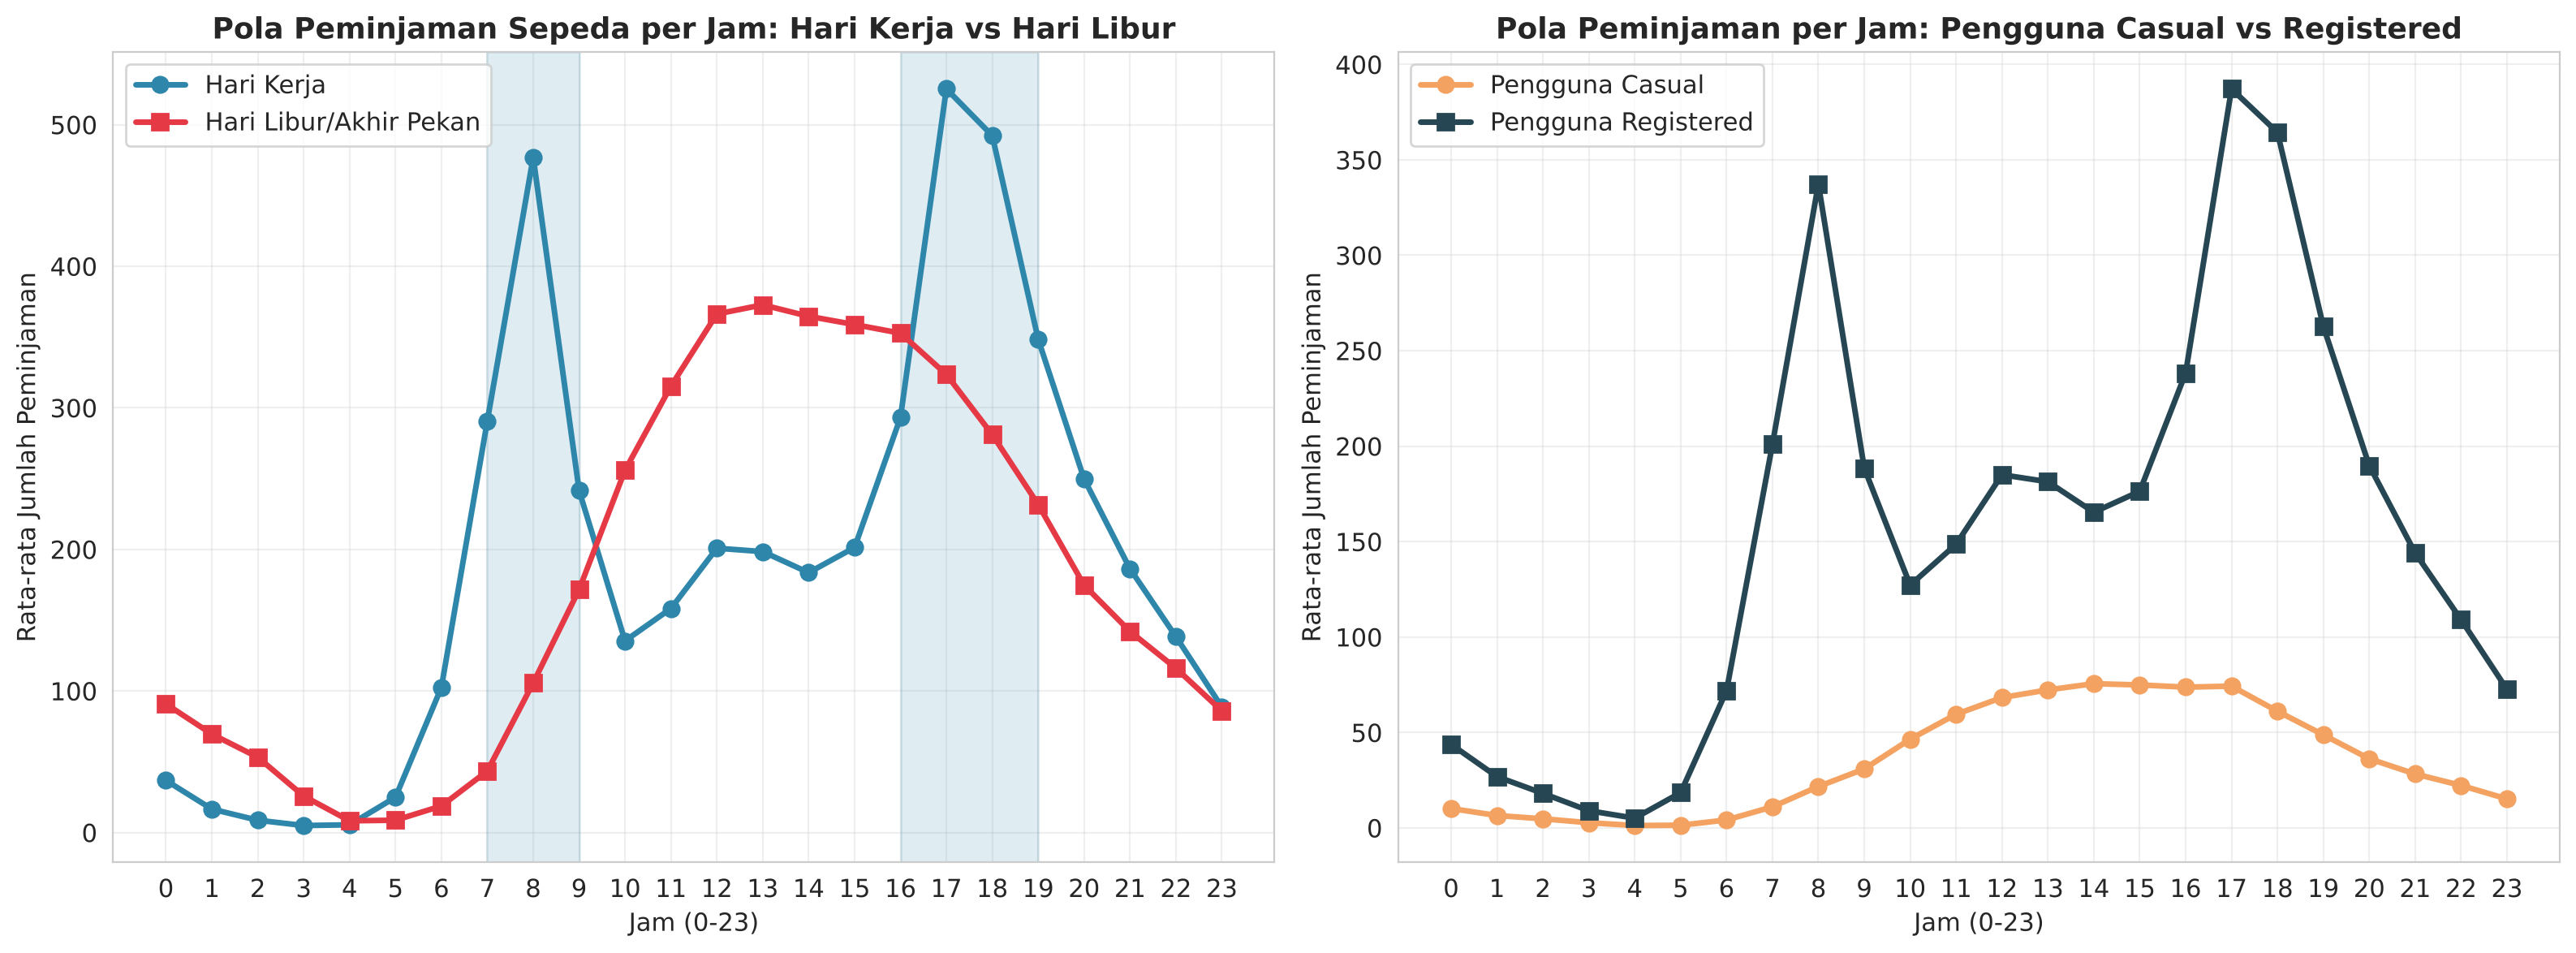

Jam puncak peminjaman pada hari kerja:
  Jam 17:00 -> rata-rata 525 peminjaman
  Jam 18:00 -> rata-rata 492 peminjaman
  Jam 08:00 -> rata-rata 477 peminjaman

Jam puncak peminjaman pada hari libur:
  Jam 13:00 -> rata-rata 373 peminjaman
  Jam 12:00 -> rata-rata 366 peminjaman
  Jam 14:00 -> rata-rata 365 peminjaman


In [7]:
# Membuat figure dengan dua subplot untuk membandingkan pola per jam dan profil pengguna
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Menghitung rata-rata peminjaman per jam pada hari kerja saja
hourly_workday = hour_df[hour_df['workingday'] == 1].groupby('hr')['cnt'].mean()
# Menghitung rata-rata peminjaman per jam pada hari libur dan akhir pekan
hourly_holiday = hour_df[hour_df['workingday'] == 0].groupby('hr')['cnt'].mean()

# Menggambar line chart peminjaman hari kerja dengan marker bulat
axes[0].plot(hourly_workday.index, hourly_workday.values, marker='o',
             linewidth=2.5, markersize=7, label='Hari Kerja', color='#2E86AB')
# Menggambar line chart peminjaman hari libur dengan marker kotak
axes[0].plot(hourly_holiday.index, hourly_holiday.values, marker='s',
             linewidth=2.5, markersize=7, label='Hari Libur/Akhir Pekan', color='#E63946')
# Menyorot jam berangkat kerja (07-09) dengan background biru transparan
axes[0].axvspan(7, 9, alpha=0.15, color='#2E86AB')
# Menyorot jam pulang kerja (16-19) dengan background biru transparan
axes[0].axvspan(16, 19, alpha=0.15, color='#2E86AB')
# Memberi judul subplot kiri
axes[0].set_title('Pola Peminjaman Sepeda per Jam: Hari Kerja vs Hari Libur',
                  fontsize=13, fontweight='bold')
# Memberi label sumbu x subplot kiri
axes[0].set_xlabel('Jam (0-23)', fontsize=11)
# Memberi label sumbu y subplot kiri
axes[0].set_ylabel('Rata-rata Jumlah Peminjaman', fontsize=11)
# Menampilkan tick pada setiap jam 0 sampai 23 agar skala jelas
axes[0].set_xticks(range(0, 24))
# Menampilkan legenda untuk membedakan hari kerja dan hari libur
axes[0].legend(fontsize=11)
# Menampilkan grid dengan transparansi rendah sebagai bantuan baca
axes[0].grid(True, alpha=0.3)

# Menghitung rata-rata jumlah pengguna casual per jam di seluruh dataset
hourly_casual = hour_df.groupby('hr')['casual'].mean()
# Menghitung rata-rata jumlah pengguna registered per jam di seluruh dataset
hourly_registered = hour_df.groupby('hr')['registered'].mean()

# Menggambar line chart pengguna casual pada subplot kanan
axes[1].plot(hourly_casual.index, hourly_casual.values, marker='o',
             linewidth=2.5, markersize=7, label='Pengguna Casual', color='#F4A261')
# Menggambar line chart pengguna registered pada subplot kanan
axes[1].plot(hourly_registered.index, hourly_registered.values, marker='s',
             linewidth=2.5, markersize=7, label='Pengguna Registered', color='#264653')
# Memberi judul subplot kanan
axes[1].set_title('Pola Peminjaman per Jam: Pengguna Casual vs Registered',
                  fontsize=13, fontweight='bold')
# Memberi label sumbu x subplot kanan
axes[1].set_xlabel('Jam (0-23)', fontsize=11)
# Memberi label sumbu y subplot kanan
axes[1].set_ylabel('Rata-rata Jumlah Peminjaman', fontsize=11)
# Menampilkan tick tiap jam agar detail per jam terlihat
axes[1].set_xticks(range(0, 24))
# Menampilkan legenda tipe pengguna
axes[1].legend(fontsize=11)
# Menampilkan grid bantu
axes[1].grid(True, alpha=0.3)

# Menyesuaikan layout agar seluruh subplot tidak bertumpuk
plt.tight_layout()
# Menampilkan chart
plt.show()

# Menampilkan label untuk jam puncak hari kerja
print('Jam puncak peminjaman pada hari kerja:')
# Mengambil tiga jam dengan rata-rata tertinggi pada hari kerja
top_workday = hourly_workday.nlargest(3)
# Melakukan perulangan untuk menampilkan tiap jam puncak dan rata-ratanya
for hr, val in top_workday.items():
    # Menampilkan jam (dua digit) beserta nilai rata-ratanya
    print(f'  Jam {hr:02d}:00 -> rata-rata {val:.0f} peminjaman')
# Menampilkan label untuk jam puncak hari libur
print('\nJam puncak peminjaman pada hari libur:')
# Mengambil tiga jam dengan rata-rata tertinggi pada hari libur
top_holiday = hourly_holiday.nlargest(3)
# Melakukan perulangan untuk menampilkan tiap jam puncak hari libur
for hr, val in top_holiday.items():
    # Menampilkan jam dan rata-ratanya
    print(f'  Jam {hr:02d}:00 -> rata-rata {val:.0f} peminjaman')

**Insight:**
- Musim Gugur dengan cuaca Cerah menjadi kombinasi paling menguntungkan dengan rata-rata peminjaman di atas 5.900 sepeda per hari, sedangkan musim Semi dengan cuaca Hujan/Salju Ringan tercatat sebagai kombinasi terendah.
- Hari kerja memperlihatkan dua puncak peminjaman pada pukul 08.00 dan 17.00 hingga 18.00, yang mengindikasikan pola commuting pekerja kantoran.
- Hari libur menampilkan pola single-peak dengan puncak sekitar pukul 12.00 hingga 14.00, menandakan pemakaian lebih bersifat rekreasi.
- Pengguna registered mendominasi pada jam commuting (pagi dan sore) sementara pengguna casual lebih banyak muncul pada siang hingga sore hari.

## Analisis Lanjutan (Opsional)

Hasil segmentasi hari berdasarkan kategori suhu:
                  rata_rata_peminjaman  total_peminjaman  jumlah_hari
temp_category                                                        
Dingin (0-10°C)                1677.77            100666           60
Sejuk (10-20°C)                3692.27           1103990          299
Hangat (20-30°C)               5661.69           1698506          300
Panas (30°C+)                  5409.96            389517           72


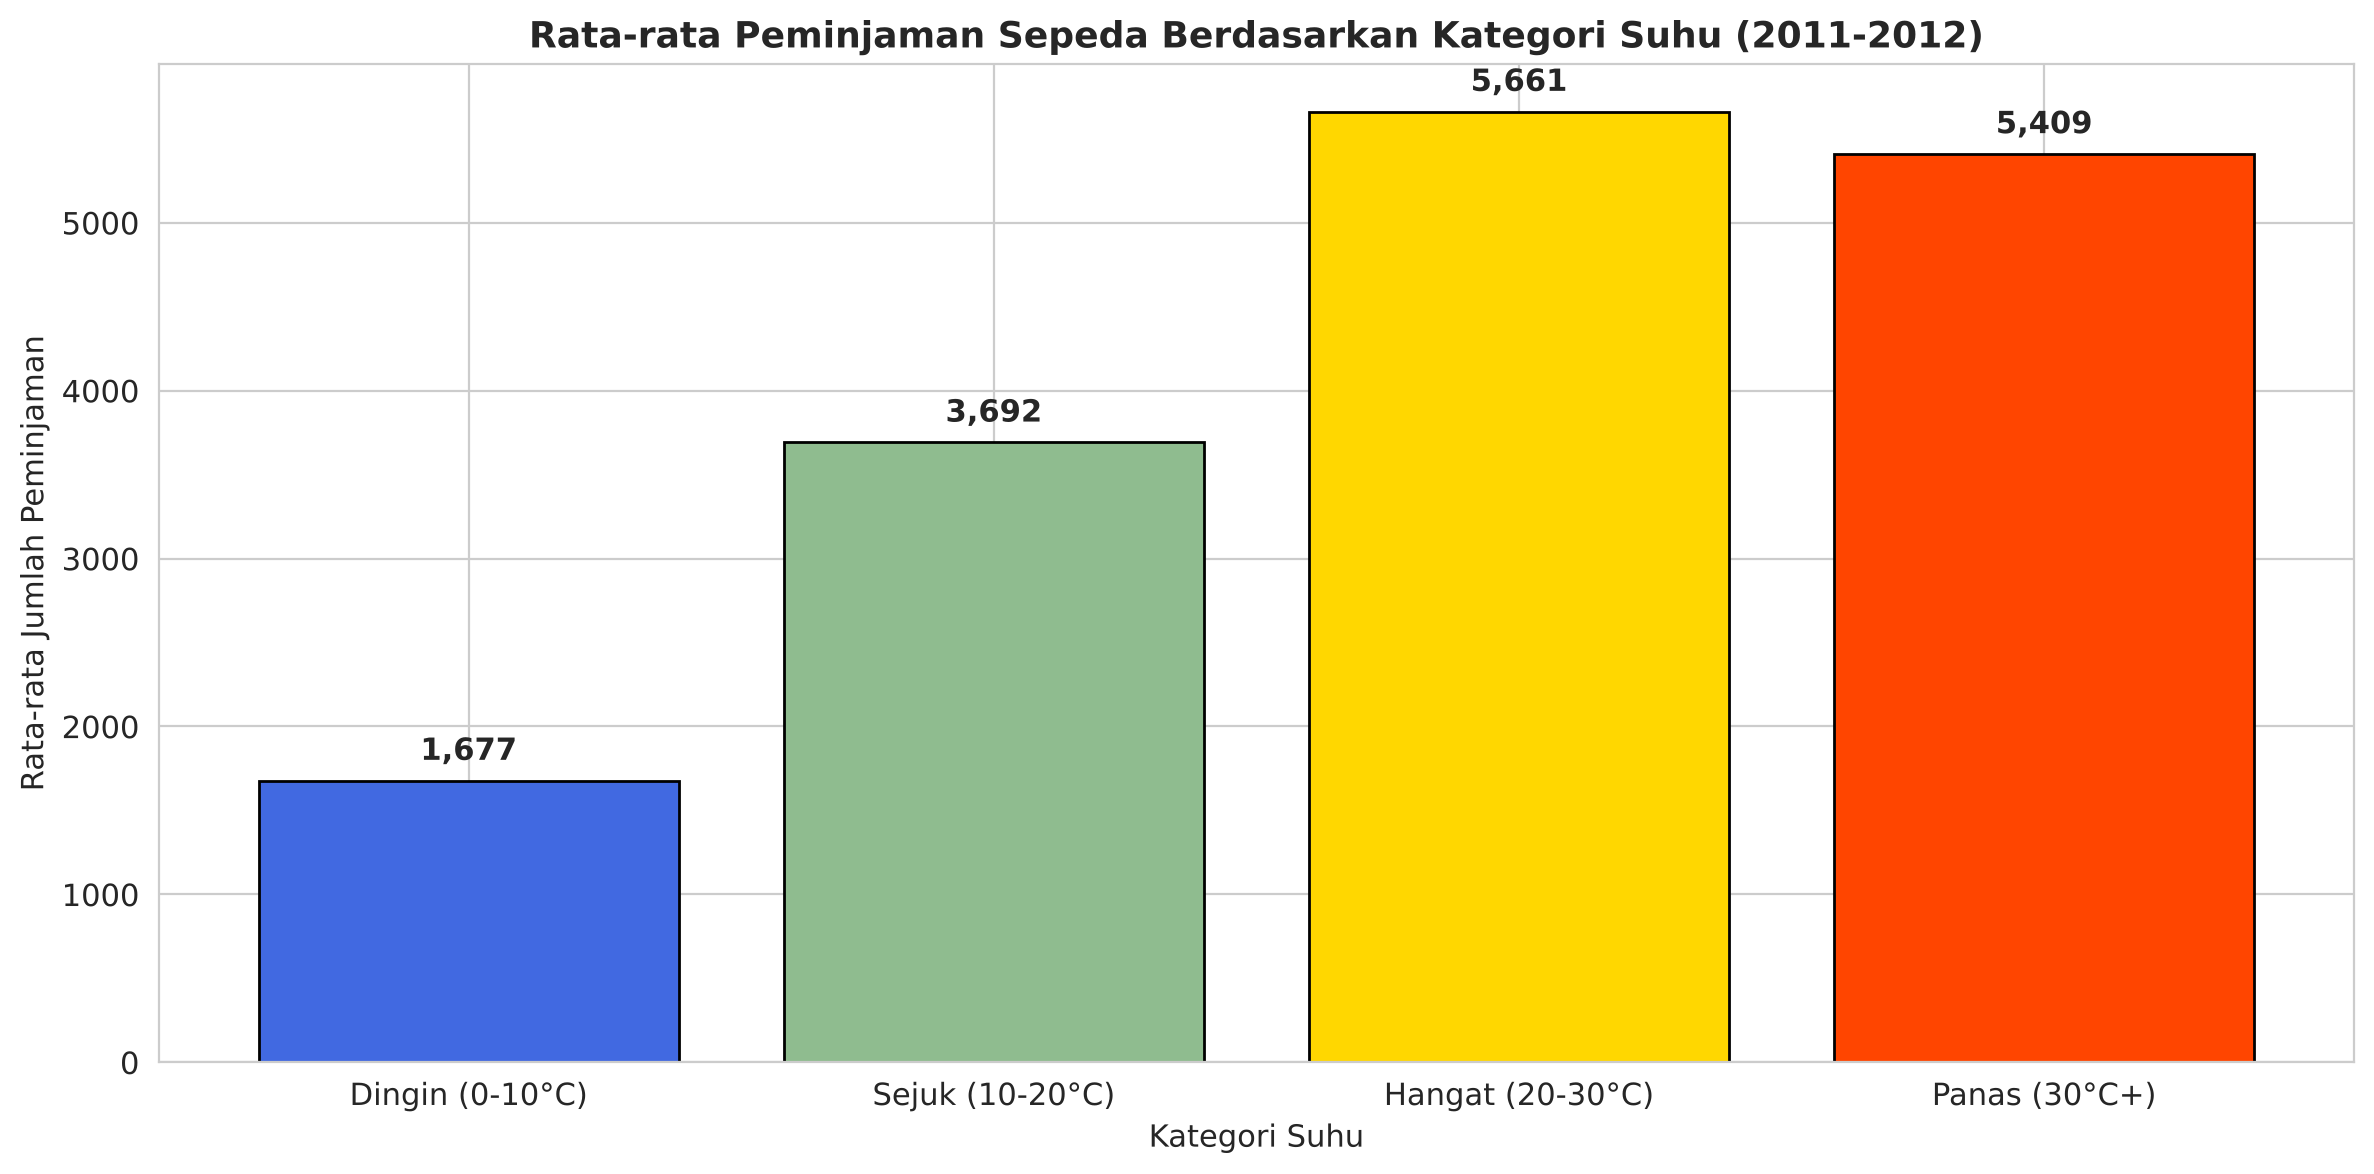


File main_data.csv berhasil disimpan ke folder dashboard/.


In [8]:
# Melakukan teknik binning (manual clustering) pada kolom suhu untuk memecah hari menjadi empat kategori
day_df['temp_category'] = pd.cut(
    day_df['temp_actual'],
    bins=[0, 10, 20, 30, 45],
    labels=['Dingin (0-10°C)', 'Sejuk (10-20°C)', 'Hangat (20-30°C)', 'Panas (30°C+)']
)

# Menghitung agregasi rata-rata, total, dan jumlah hari untuk tiap kategori suhu
temp_analysis = day_df.groupby('temp_category', observed=True).agg(
    rata_rata_peminjaman=('cnt', 'mean'),
    total_peminjaman=('cnt', 'sum'),
    jumlah_hari=('cnt', 'count')
).round(2)

# Menampilkan label untuk hasil clustering suhu
print('Hasil segmentasi hari berdasarkan kategori suhu:')
# Menampilkan tabel ringkasan hasil binning suhu
print(temp_analysis)

# Membuat figure untuk visualisasi hasil binning
plt.figure(figsize=(12, 6))
# Mendefinisikan warna yang mencerminkan intensitas suhu dari dingin ke panas
colors_temp = ['#4169E1', '#8FBC8F', '#FFD700', '#FF4500']
# Menggambar bar chart rata-rata peminjaman per kategori suhu
bars = plt.bar(temp_analysis.index.astype(str),
               temp_analysis['rata_rata_peminjaman'],
               color=colors_temp, edgecolor='black')
# Memberi judul chart yang menegaskan konteks binning
plt.title('Rata-rata Peminjaman Sepeda Berdasarkan Kategori Suhu (2011-2012)',
          fontsize=13, fontweight='bold')
# Memberi label sumbu x
plt.xlabel('Kategori Suhu', fontsize=11)
# Memberi label sumbu y
plt.ylabel('Rata-rata Jumlah Peminjaman', fontsize=11)
# Menambahkan anotasi angka pada tiap batang untuk kemudahan pembacaan
for bar in bars:
    # Mengambil tinggi batang
    height = bar.get_height()
    # Menulis angka rata-rata di atas batang
    plt.text(bar.get_x() + bar.get_width()/2, height + 80,
             f'{int(height):,}', ha='center', va='bottom', fontsize=11, fontweight='bold')
# Merapikan layout agar tidak terpotong
plt.tight_layout()
# Menampilkan chart
plt.show()

# Mengimpor modul os untuk membuat folder output dashboard
import os
# Memastikan folder dashboard tersedia agar penyimpanan main_data.csv tidak gagal
os.makedirs('dashboard', exist_ok=True)
# Menyimpan day_df yang sudah diperkaya label ke CSV untuk kebutuhan dashboard
day_df.to_csv('dashboard/main_data.csv', index=False)
# Menampilkan konfirmasi penyimpanan berhasil
print('\nFile main_data.csv berhasil disimpan ke folder dashboard/.')

**Insight:**
- Teknik binning suhu (clustering manual) membagi 731 hari observasi ke dalam empat kategori yang membantu perencanaan armada secara lebih praktis.
- Kategori suhu Hangat (20-30°C) mencatat rata-rata peminjaman tertinggi sebesar 5.662 sepeda per hari pada 300 hari observasi.
- Kategori suhu Dingin (0-10°C) hanya mencatat rata-rata 1.678 peminjaman per hari, yang berarti kebutuhan armada pada hari dingin kurang dari sepertiga hari hangat.
- Hasil segmentasi ini dapat langsung dipakai untuk menyusun jadwal distribusi sepeda berbasis prakiraan cuaca harian.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Musim dan kondisi cuaca memberikan pengaruh signifikan terhadap rata-rata peminjaman sepeda harian di Washington D.C. selama periode 2011 hingga 2012. Musim Gugur mencatat rata-rata peminjaman tertinggi sebesar 5.644 sepeda per hari, diikuti musim Panas 4.992, musim Dingin 4.728, dan musim Semi di urutan terakhir dengan 2.604 peminjaman. Dari sisi cuaca, hari Cerah menghasilkan rata-rata 4.877 peminjaman sementara hari Hujan/Salju Ringan hanya 1.803 peminjaman. Kombinasi paling menguntungkan adalah musim Gugur dengan cuaca Cerah yang menyentuh rata-rata di atas 5.900 peminjaman per hari, sedangkan kombinasi terburuk adalah musim Semi dengan cuaca Hujan/Salju Ringan.
- **Conclusion pertanyaan 2:** Pola peminjaman per jam memperlihatkan dua karakter berbeda antara hari kerja dan hari libur. Pada hari kerja terjadi dua puncak peminjaman yaitu pukul 08.00 dengan rata-rata 495 peminjaman per jam dan pukul 17.00 dengan rata-rata 525 peminjaman per jam, yang menunjukkan pola commuting. Pada hari libur puncak tunggal muncul pada siang hari sekitar pukul 13.00 dengan rata-rata 373 peminjaman per jam. Pengguna registered mendominasi jam commuting hari kerja, sedangkan pengguna casual berkontribusi lebih besar pada siang hingga sore hari libur.

**Rekomendasi Action Item:**
- Memperbanyak jumlah armada sepeda pada musim Gugur dan musim Panas, terutama di hari dengan cuaca Cerah, karena rata-rata permintaan dapat mencapai dua kali lipat dibandingkan musim Semi.
- Menyusun jadwal maintenance armada pada musim Semi atau hari dengan prakiraan cuaca Hujan/Salju Ringan, mengingat permintaan menurun drastis pada kondisi tersebut.
- Menyiapkan kapasitas tambahan di stasiun dekat pusat perkantoran pada hari kerja pukul 07.00 sampai 09.00 dan pukul 16.00 sampai 19.00 untuk mengakomodasi pola commuting pengguna registered.
- Membuat program promosi khusus pengguna casual pada hari libur siang hari, misalnya paket sewa keluarga atau tiket wisata bersepeda, untuk mendorong konversi menjadi pengguna registered.
- Menggunakan hasil segmentasi suhu sebagai dasar prediksi kebutuhan armada harian dengan merujuk prakiraan cuaca satu hari sebelumnya.